In [51]:
!pip install catboost


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\phuc0\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [22]:
# Cell 0: Cài đặt các thư viện cần thiết cho Notebook
import sys
!{sys.executable} -m pip install pymysql pandas cryptography

In [24]:
# Cell 1: Kết nối an toàn tới MySQL của TáoCare
import getpass
import pymysql
import pandas as pd

# Thông số kết nối MySQL TáoCare
HOST = '127.0.0.1'
PORT = 3307
DB_NAME = 'apple_repair_service'

# Nhập thông tin xác thực từ bàn phím
db_user = input("Nhập MySQL Username (mặc định 'root'): ") or 'root'
db_password = getpass.getpass("Nhập MySQL Password: ")

try:
    connection = pymysql.connect(
        host=HOST,
        port=PORT,
        user=db_user,
        password=db_password,
        database=DB_NAME,
        cursorclass=pymysql.cursors.DictCursor,
        autocommit=True
    )
    print("Kết nối MySQL TáoCare thành công!")
except Exception as e:
    print(f"❌ Lỗi kết nối MySQL: {e}")

Kết nối MySQL TáoCare thành công!


In [25]:
# 1. Xác nhận database đang kết nối
with connection.cursor() as cursor:
    cursor.execute("SELECT DATABASE() AS database_name")
    print("Database hiện tại:", cursor.fetchone())

# 2. Liệt kê các bảng trong database
with connection.cursor() as cursor:
    cursor.execute("""
        SELECT TABLE_NAME
        FROM information_schema.TABLES
        WHERE TABLE_SCHEMA = DATABASE()
          AND TABLE_TYPE = 'BASE TABLE'
        ORDER BY TABLE_NAME
    """)
    tables = cursor.fetchall()

table_df = pd.DataFrame(tables)

print("Tổng số bảng:", len(table_df))
display(table_df)

Database hiện tại: {'database_name': 'apple_repair_service'}
Tổng số bảng: 33


,TABLE_NAME
0,appointment_date_overrides
1,appointment_devices
2,appointment_service_items
3,appointment_slots
4,appointment_weekly_schedules
5,appointments
6,assignments
7,branch_inventories
8,branches
9,customer_devices


In [26]:
# Cell 2: Đếm số lượng dòng của các bảng quan trọng
tables_to_check = [
    'service_tickets',
    'repair_items',
    'assignments',
    'service_status_histories',
    'service_catalog_items',
    'service_types',
    'service_issues',
    'customer_devices',
    'device_models',
    'device_types',
    'transfers'
]

row_counts = []

with connection.cursor() as cursor:
    for table in tables_to_check:
        try:
            cursor.execute(f"SELECT COUNT(*) AS total FROM `{table}`;")
            count = cursor.fetchone()['total']
            row_counts.append({'Tên Bảng': table, 'Số Dòng (Rows)': count})
        except Exception as err:
            row_counts.append({'Tên Bảng': table, 'Số Dòng (Rows)': f"LỖI: {err}"})

df_counts = pd.DataFrame(row_counts)
display(df_counts)

,Tên Bảng,Số Dòng (Rows)
0,service_tickets,6
1,repair_items,7
2,assignments,3
3,service_status_histories,24
4,service_catalog_items,304
5,service_types,3
6,service_issues,5
7,customer_devices,6
8,device_models,64
9,device_types,5


In [27]:
# Cell 3: Xem danh sách cột chuẩn xác của 4 bảng lõi
core_tables = ['service_tickets', 'repair_items', 'assignments', 'service_status_histories']

for table_name in core_tables:
    with connection.cursor() as cursor:
        cursor.execute(f"DESCRIBE `{table_name}`;")
        rows = cursor.fetchall()
        
    df_cols = pd.DataFrame(rows)
    print(f"\nCấu trúc bảng: {table_name.upper()}")
    if not df_cols.empty and 'Field' in df_cols.columns:
        display(df_cols[['Field', 'Type', 'Null', 'Key']])
    else:
        display(df_cols)


Cấu trúc bảng: SERVICE_TICKETS


,Field,Type,Null,Key
0,id,bigint,NO,PRI
1,cancel_reason,text,YES,
2,discount_percent,"decimal(5,2)",NO,
3,handed_over_at,datetime(6),YES,
4,inspection_result,text,YES,
5,paid_at,datetime(6),YES,
6,payment_method,"enum('BANK_TRANSFER','CARD','CASH','OTHER')",YES,
7,payment_status,"enum('PAID','PENDING')",NO,
8,received_at,datetime(6),NO,
9,received_condition,text,YES,



Cấu trúc bảng: REPAIR_ITEMS


,Field,Type,Null,Key
0,id,bigint,NO,PRI
1,approval_decision_at,datetime(6),YES,
2,approval_note,text,YES,
3,approval_status,"enum('APPROVED','PENDING','REJECTED')",NO,
4,base_price,"decimal(18,2)",YES,
5,created_at,datetime(6),NO,
6,final_price,"decimal(18,2)",YES,
7,item_name_snapshot,varchar(255),NO,
8,updated_at,datetime(6),NO,
9,warranty_decision,"enum('APPROVED','REJECTED')",YES,



Cấu trúc bảng: ASSIGNMENTS


,Field,Type,Null,Key
0,id,bigint,NO,PRI
1,assigned_at,datetime(6),NO,
2,ended_at,datetime(6),YES,
3,note,text,YES,
4,source,"enum('ACCEPTED_RECOMMENDATION','MANUAL_OVERRID...",NO,
5,status,"enum('ACTIVE','ENDED')",NO,
6,assigned_by,bigint,NO,MUL
7,service_ticket_id,bigint,NO,MUL
8,technician_id,bigint,NO,MUL



Cấu trúc bảng: SERVICE_STATUS_HISTORIES


,Field,Type,Null,Key
0,id,bigint,NO,PRI
1,changed_at,datetime(6),NO,
2,from_status,"enum('ASSIGNED','CANCELLED','HANDED_OVER','INS...",YES,
3,note,text,YES,
4,to_status,"enum('ASSIGNED','CANCELLED','HANDED_OVER','INS...",NO,
5,changed_by,bigint,YES,MUL
6,service_ticket_id,bigint,NO,MUL
7,resolution_note,text,YES,
8,resolution_recorded_at,datetime(6),YES,
9,resolved_at,datetime(6),YES,


In [28]:
# Cell 4 (Sửa tên cột): Đọc dữ liệu tổng hợp bằng JOIN
query_raw_data = """
SELECT 
    st.id AS ticket_id,
    st.ticket_code,
    st.branch_id,
    st.status AS ticket_status,
    st.received_at AS ticket_received_at,
    
    cd.id AS customer_device_id,
    dt.name AS device_type_name,
    dm.name AS device_model_name,
    
    ri.id AS repair_item_id,
    ri.approval_status,
    ri.warranty_source_item_id,
    sci.id AS catalog_item_id,
    sci.name AS catalog_item_name,
    sci.standard_duration_minutes,
    si.name AS issue_name,
    styp.name AS service_type_name,
    
    asn.id AS assignment_id,
    asn.technician_id,
    asn.status AS assignment_status,
    asn.assigned_at,
    asn.ended_at
FROM service_tickets st
JOIN customer_devices cd ON st.customer_device_id = cd.id
JOIN device_models dm ON cd.device_model_id = dm.id
JOIN device_types dt ON dm.device_type_id = dt.id
LEFT JOIN repair_items ri ON ri.service_ticket_id = st.id
LEFT JOIN service_catalog_items sci ON ri.service_catalog_item_id = sci.id
LEFT JOIN service_issues si ON sci.service_issue_id = si.id
LEFT JOIN service_types styp ON sci.service_type_id = styp.id
LEFT JOIN assignments asn ON asn.service_ticket_id = st.id
ORDER BY st.id ASC, ri.id ASC, asn.id ASC;
"""

with connection.cursor() as cursor:
    cursor.execute(query_raw_data)
    raw_rows = cursor.fetchall()

df_raw = pd.DataFrame(raw_rows)
print(f"Tổng số dòng truy vấn thô (Raw JOIN): {len(df_raw)}")
display(df_raw.head(10))

Tổng số dòng truy vấn thô (Raw JOIN): 7


,ticket_id,ticket_code,branch_id,ticket_status,ticket_received_at,customer_device_id,device_type_name,device_model_name,repair_item_id,approval_status,...,catalog_item_id,catalog_item_name,standard_duration_minutes,issue_name,service_type_name,assignment_id,technician_id,assignment_status,assigned_at,ended_at
0,1505,ST-20261009-52AD57E3A3B7,1070,HANDED_OVER,2026-10-09 20:54:19.773408,1505,AirPods,Airpods Pro 3,1657,APPROVED,...,2512,Sửa chữa pin Airpods Pro 3,45,Pin,Sửa chữa,465.0,5343.0,ENDED,2026-10-09 20:55:26.794769,2026-10-09 20:59:23.861107
1,1506,ST-20261009-773A93B42726,1070,HANDED_OVER,2026-10-09 21:02:59.208555,1506,iPhone,13,1658,REJECTED,...,2558,Sửa chữa màn hình 13,60,Màn hình,Sửa chữa,466.0,5343.0,ENDED,2026-10-09 21:03:33.192244,2026-10-09 21:06:30.495408
2,1506,ST-20261009-773A93B42726,1070,HANDED_OVER,2026-10-09 21:02:59.208555,1506,iPhone,13,1659,APPROVED,...,2733,Thay màn hình iPhone 13 OLED — Deji OLED,45,Màn hình,Thay thế linh kiện,466.0,5343.0,ENDED,2026-10-09 21:03:33.192244,2026-10-09 21:06:30.495408
3,1507,ST-20261010-AC94E2F04EB5,1070,HANDED_OVER,2026-10-10 11:08:53.627428,1508,iPad,Ipad Air 2,1660,APPROVED,...,2507,Sửa chữa màn hình Ipad Air 2,90,Màn hình,Sửa chữa,467.0,5343.0,ENDED,2026-10-10 11:09:49.703545,2026-10-10 11:12:37.215409
4,1508,ST-20261010-6DB35F095CEA,1070,CANCELLED,2026-10-10 19:50:24.854020,1511,iPhone,15 Pro,1661,APPROVED,...,2473,Sửa chữa camera 15 Pro,60,Camera,Sửa chữa,NaN,NaN,None,NaT,NaT
5,1509,ST-20261014-BEBCCDC43396,1070,CANCELLED,2026-10-14 14:08:33.708813,1513,Apple Watch,Apple Watch Series 6,1662,APPROVED,...,2687,Sửa chữa màn hình Apple Watch Series 6,60,Màn hình,Sửa chữa,NaN,NaN,None,NaT,NaT
6,1510,ST-20261014-740A29D1D425,1070,CANCELLED,2026-10-14 20:48:35.413815,1515,AirPods,Airpods 5,1663,APPROVED,...,2509,Sửa chữa pin Airpods 5,45,Pin,Sửa chữa,NaN,NaN,None,NaT,NaT


In [48]:
# ==============================================================================
# Cell 5: LỌC MẪU RÁC & MẪU CHUYỂN GIAO (EXACT LINK VIA from_assignment_id)
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Truy vấn lấy danh sách ca phân công bị CHUYỂN GIAO từ bảng 'transfers'
# Dùng from_assignment_id JOIN với assignments để lấy toàn bộ các khóa liên kết
query_transfers = """
SELECT DISTINCT 
    t.from_assignment_id AS assignment_id,
    a.repair_item_id,
    a.service_ticket_id AS ticket_id
FROM transfers t
LEFT JOIN assignments a ON t.from_assignment_id = a.id
WHERE t.from_assignment_id IS NOT NULL;
"""

transferred_assignment_ids = set()
transferred_ticket_ids = set()
transferred_repair_item_ids = set()

try:
    with connection.cursor() as cursor:
        cursor.execute(query_transfers)
        rows = cursor.fetchall()
        for r in rows:
            if isinstance(r, dict):
                if r.get('assignment_id'): transferred_assignment_ids.add(r['assignment_id'])
                if r.get('ticket_id'): transferred_ticket_ids.add(r['ticket_id'])
                if r.get('repair_item_id'): transferred_repair_item_ids.add(r['repair_item_id'])
            else:
                if r[0]: transferred_assignment_ids.add(r[0])
                if r[1]: transferred_repair_item_ids.add(r[1])
                if r[2]: transferred_ticket_ids.add(r[2])
except Exception:
    # Phương án dự phòng: Chỉ lấy trực tiếp từ bảng transfers
    query_simple = "SELECT DISTINCT from_assignment_id FROM transfers WHERE from_assignment_id IS NOT NULL;"
    with connection.cursor() as cursor:
        cursor.execute(query_simple)
        rows = cursor.fetchall()
        transferred_assignment_ids = set([r['from_assignment_id'] if isinstance(r, dict) else r[0] for r in rows])

# 2. Danh sách trạng thái phiếu không hợp lệ (Hủy, Từ chối, Nháp)
INVALID_TICKET_STATUSES = ['CANCELLED', 'REJECTED', 'DRAFT']

# 3. Tiến hành lọc tập dữ liệu thô (df_raw)

# Bước 3.1: Loại bỏ phiếu có trạng thái bị Hủy / Từ chối / Nháp
df_step1 = df_raw[~df_raw['ticket_status'].isin(INVALID_TICKET_STATUSES)].copy()

# Bước 3.2: Loại bỏ hoàn toàn các ca bị CHUYỂN GIAO giữa các KTV
filter_col = 'None'
if 'assignment_id' in df_step1.columns and len(transferred_assignment_ids) > 0:
    filter_col = 'assignment_id'
    df_step2 = df_step1[~df_step1['assignment_id'].isin(transferred_assignment_ids)].copy()
elif 'ticket_id' in df_step1.columns and len(transferred_ticket_ids) > 0:
    filter_col = 'ticket_id'
    df_step2 = df_step1[~df_step1['ticket_id'].isin(transferred_ticket_ids)].copy()
elif 'repair_item_id' in df_step1.columns and len(transferred_repair_item_ids) > 0:
    filter_col = 'repair_item_id'
    df_step2 = df_step1[~df_step1['repair_item_id'].isin(transferred_repair_item_ids)].copy()
else:
    df_step2 = df_step1.copy()

# Bước 3.3: Lọc các ca thiếu mốc thời gian nhận/trả ca (assigned_at & ended_at bắt buộc phải NOT NULL)
df_eligible = df_step2[
    df_step2['assigned_at'].notnull() & 
    df_step2['ended_at'].notnull()
].copy()

# Kiểm tra logic: thời điểm kết thúc ca phải diễn ra sau thời điểm nhận ca
df_eligible['assigned_at'] = pd.to_datetime(df_eligible['assigned_at'])
df_eligible['ended_at'] = pd.to_datetime(df_eligible['ended_at'])
df_eligible = df_eligible[df_eligible['ended_at'] > df_eligible['assigned_at']].copy()

# Reset index làm sạch dataframe
df_eligible.reset_index(drop=True, inplace=True)

# 4. In báo cáo kiểm định chất lượng lọc mẫu
print("\n=== BÁO CÁO KẾT QUẢ LỌC DỮ LIỆU ĐỦ ĐIỀU KIỆN (CELL 5) ===")
print(f"- Số mẫu thô ban đầu (df_raw): {len(df_raw)} mẫu")
print(f"- Loại bỏ do trạng thái Hủy/Từ chối/Nháp: {len(df_raw) - len(df_step1)} mẫu")
print(f"- Loại bỏ do bị CHUYỂN GIAO (transfers): {len(df_step1) - len(df_step2)} mẫu (Khóa lọc: '{filter_col}')")
print(f"- Loại bỏ do sai/thiếu mốc thời gian phân công: {len(df_step2) - len(df_eligible)} mẫu")
print(f"------------------------------------------------------------------")
print(f"✅ TỔNG SỐ PHIẾU CHUẨN ĐỦ ĐIỀU KIỆN (df_eligible): {len(df_eligible)} mẫu")

display(df_eligible[['ticket_id', 'repair_item_id', 'technician_id', 'ticket_status', 'assigned_at', 'ended_at']].head())


=== BÁO CÁO KẾT QUẢ LỌC DỮ LIỆU ĐỦ ĐIỀU KIỆN (CELL 5) ===
- Số mẫu thô ban đầu (df_raw): 7 mẫu
- Loại bỏ do trạng thái Hủy/Từ chối/Nháp: 3 mẫu
- Loại bỏ do bị CHUYỂN GIAO (transfers): 0 mẫu (Khóa lọc: 'None')
- Loại bỏ do sai/thiếu mốc thời gian phân công: 0 mẫu
------------------------------------------------------------------
✅ TỔNG SỐ PHIẾU CHUẨN ĐỦ ĐIỀU KIỆN (df_eligible): 4 mẫu


,ticket_id,repair_item_id,technician_id,ticket_status,assigned_at,ended_at
0,1505,1657,5343.0,HANDED_OVER,2026-10-09 20:55:26.794769,2026-10-09 20:59:23.861107
1,1506,1658,5343.0,HANDED_OVER,2026-10-09 21:03:33.192244,2026-10-09 21:06:30.495408
2,1506,1659,5343.0,HANDED_OVER,2026-10-09 21:03:33.192244,2026-10-09 21:06:30.495408
3,1507,1660,5343.0,HANDED_OVER,2026-10-10 11:09:49.703545,2026-10-10 11:12:37.215409


In [ ]:
# Cell 6: Đọc service_status_histories và tính actual_technical_minutes
eligible_ticket_ids = df_eligible['ticket_id'].tolist()

# 1. Truy xuất toàn bộ lịch sử trạng thái của các ticket đủ điều kiện
query_history = f"""
SELECT 
    service_ticket_id AS ticket_id,
    from_status,
    to_status,
    changed_at
FROM service_status_histories
WHERE service_ticket_id IN ({','.join(map(str, eligible_ticket_ids))})
ORDER BY service_ticket_id ASC, changed_at ASC;
"""

with connection.cursor() as cursor:
    cursor.execute(query_history)
    history_rows = cursor.fetchall()

df_history = pd.DataFrame(history_rows)
print("Lịch sử thay đổi trạng thái của 3 ticket đủ điều kiện:")
display(df_history)

# 2. Thuật toán tính tổng phút kỹ thuật (INSPECTING + REPAIRING)
TECHNICAL_STATUSES = {'INSPECTING', 'REPAIRING'}

target_results = []

for idx, sample in df_eligible.iterrows():
    t_id = sample['ticket_id']
    assigned_at = pd.to_datetime(sample['assigned_at'])
    ended_at = pd.to_datetime(sample['ended_at'])
    
    # Lọc lịch sử của ticket hiện tại
    t_history = df_history[df_history['ticket_id'] == t_id].sort_values('changed_at').copy()
    
    total_technical_seconds = 0.0
    
    # Lặp qua từng mốc chuyển trạng thái
    for i in range(len(t_history)):
        curr_row = t_history.iloc[i]
        curr_status = curr_row['to_status']
        start_time = pd.to_datetime(curr_row['changed_at'])
        
        # Chỉ xét nếu trạng thái hiện tại là INSPECTING hoặc REPAIRING
        if curr_status in TECHNICAL_STATUSES:
            # Xác định thời điểm kết thúc trạng thái này (mốc đổi status tiếp theo hoặc ended_at của assignment)
            if i + 1 < len(t_history):
                end_time = pd.to_datetime(t_history.iloc[i + 1]['changed_at'])
            else:
                end_time = ended_at
                
            # Cắt khoảng thời gian nằm trong phạm vi assignment [assigned_at, ended_at]
            effective_start = max(start_time, assigned_at)
            effective_end = min(end_time, ended_at)
            
            if effective_end > effective_start:
                duration_sec = (effective_end - effective_start).total_seconds()
                total_technical_seconds += duration_sec

    # Quy đổi sang phút
    actual_minutes = round(total_technical_seconds / 60.0, 2)
    
    # Tính tổng thời gian assignment (từ lúc gán KTV đến kết thúc) để đối chiếu
    total_assignment_minutes = round((ended_at - assigned_at).total_seconds() / 60.0, 2)
    
    target_results.append({
        'ticket_id': t_id,
        'assigned_at': assigned_at,
        'ended_at': ended_at,
        'total_assignment_minutes': total_assignment_minutes,
        'actual_technical_minutes': actual_minutes
    })

df_targets = pd.DataFrame(target_results)

print("\nKẾT QUẢ TÍNH TARGET (actual_technical_minutes):")
display(df_targets)

Lịch sử thay đổi trạng thái của 3 ticket đủ điều kiện:


,ticket_id,from_status,to_status,changed_at
0,1505,None,WAITING_ASSIGNMENT,2026-10-09 20:54:19.798704
1,1505,WAITING_ASSIGNMENT,ASSIGNED,2026-10-09 20:55:26.809158
2,1505,ASSIGNED,INSPECTING,2026-10-09 20:56:47.884929
3,1505,INSPECTING,REPAIRING,2026-10-09 20:58:57.060102
4,1505,REPAIRING,WAITING_HANDOVER,2026-10-09 20:59:23.861107
5,1505,WAITING_HANDOVER,HANDED_OVER,2026-10-09 21:00:26.173620
6,1506,None,WAITING_ASSIGNMENT,2026-10-09 21:02:59.216406
7,1506,WAITING_ASSIGNMENT,ASSIGNED,2026-10-09 21:03:33.197941
8,1506,ASSIGNED,INSPECTING,2026-10-09 21:04:36.107249
9,1506,INSPECTING,REPAIRING,2026-10-09 21:05:54.386983



KẾT QUẢ TÍNH TARGET (actual_technical_minutes):


,ticket_id,assigned_at,ended_at,total_assignment_minutes,actual_technical_minutes
0,1505,2026-10-09 20:55:26.794769,2026-10-09 20:59:23.861107,3.95,2.60
1,1506,2026-10-09 21:03:33.192244,2026-10-09 21:06:30.495408,2.96,1.91
2,1507,2026-10-10 11:09:49.703545,2026-10-10 11:12:37.215409,2.79,1.21


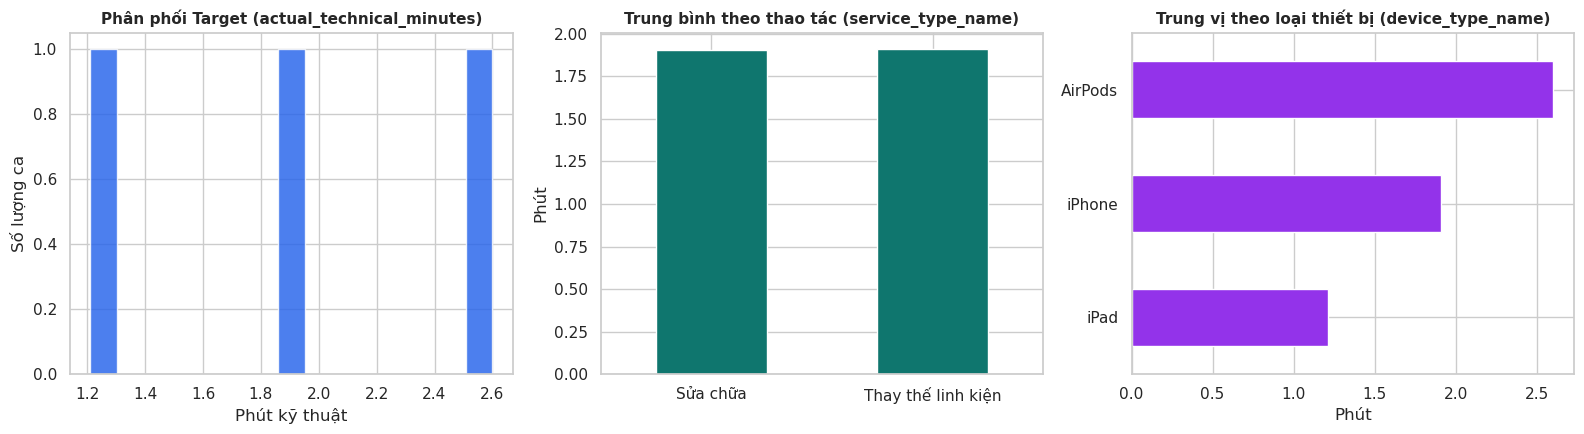

In [39]:
import matplotlib.pyplot as plt

# 1. Định nghĩa tên cột chuẩn theo Data Schema TáoCare
TARGET = 'actual_technical_minutes'
eda = df_dataset  # Hoặc df_final nếu đã chạy qua Cell 7

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Biểu đồ 1: Phân phối thời gian làm kỹ thuật thực tế
axes[0].hist(eda[TARGET], bins=15, color='#2563eb', alpha=0.82, edgecolor='white')
axes[0].set_title('Phân phối Target (actual_technical_minutes)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Phút kỹ thuật')
axes[0].set_ylabel('Số lượng ca')

# Biểu đồ 2: Thời gian trung bình theo loại thao tác kỹ thuật (service_type_name)
eda.groupby('service_type_name', observed=False)[TARGET].mean().plot.bar(
    ax=axes[1], color='#0f766e', rot=0
)
axes[1].set_title('Trung bình theo thao tác (service_type_name)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Phút')

# Biểu đồ 3: Thời gian trung vị theo loại thiết bị (device_type_name)
eda.groupby('device_type_name', observed=False)[TARGET].median().sort_values().plot.barh(
    ax=axes[2], color='#9333ea'
)
axes[2].set_title('Trung vị theo loại thiết bị (device_type_name)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Phút')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

=== TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG SỐ VỚI TARGET (actual_technical_minutes) ===


,correlation_with_target
tech_issue_avg_duration,0.870896
tech_catalog_avg_duration,0.870896
tech_catalog_efficiency_ratio,0.870896
tech_issue_efficiency_ratio,0.870896
tech_efficiency_ratio,0.867454
tech_avg_duration,0.867454
prediction_weekday,-0.868095
standard_duration_minutes,-0.868095
tech_issue_jobs,-0.868095
tech_total_jobs,-0.999991


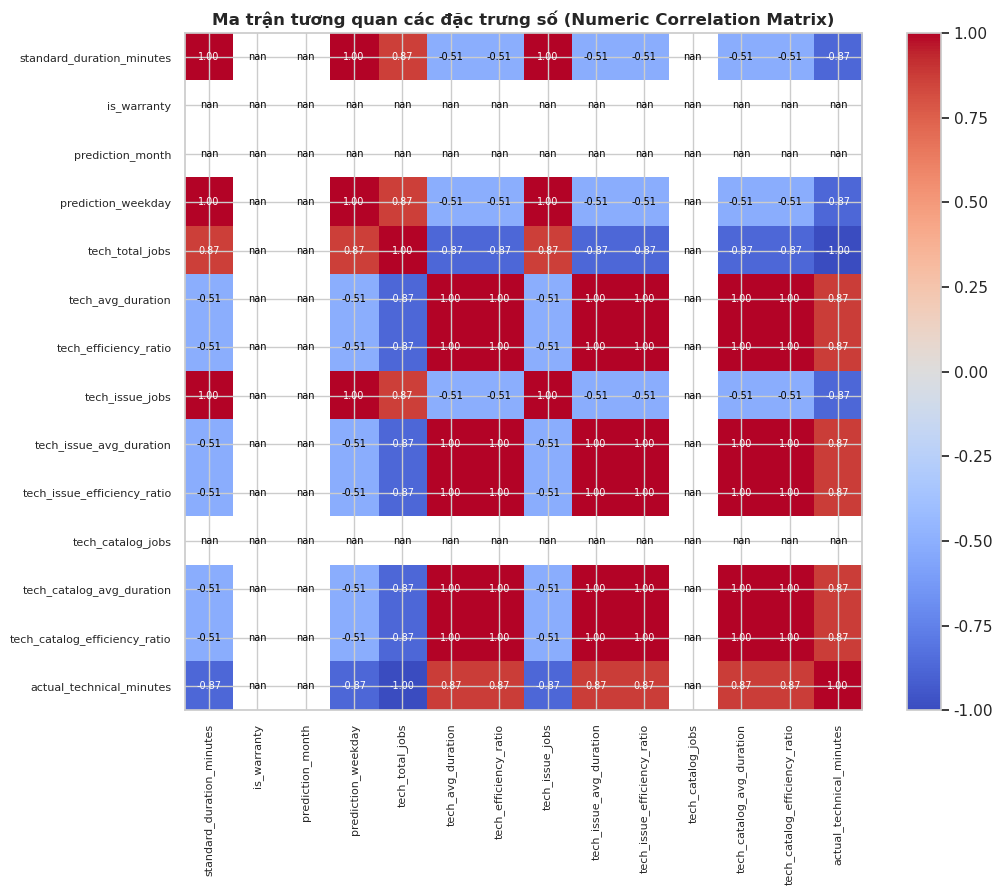

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Thiết lập biến mục tiêu và nguồn dữ liệu
TARGET = 'actual_technical_minutes'
eda_df = df_final.copy() if 'df_final' in locals() else df_feat.copy()

# 2. Lọc các cột số, loại bỏ các cột ID không có giá trị tương quan
ignore_cols = ['ticket_id', 'repair_item_id', 'technician_id', 'branch_id']
num_df = eda_df.select_dtypes(include=[np.number]).drop(
    columns=[c for c in ignore_cols if c in eda_df.columns], errors='ignore'
)

# 3. Tính toán Ma trận tương quan và Tương quan riêng với Target
corr_matrix = num_df.corr()
target_corr = corr_matrix[TARGET].drop(TARGET).sort_values(ascending=False)

# Hiển thị Bảng tương quan của từng đặc trưng với Target
print("=== TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG SỐ VỚI TARGET (actual_technical_minutes) ===")
display(target_corr.rename('correlation_with_target').to_frame())

# 4. Trực quan hóa Heatmap Ma trận Tương quan
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

# Thiết lập nhãn cho các trục
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.index, fontsize=8)

# Bổ sung giá trị số (Annotation) trực tiếp lên từng ô heatmap cho dễ quan sát
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        val = corr_matrix.iloc[i, j]
        ax.text(
            j,
            i,
            f"{val:.2f}",
            ha='center',
            va='center',
            color='white' if abs(val) > 0.55 else 'black',
            fontsize=7,
        )

fig.colorbar(image, ax=ax)
ax.set_title('Ma trận tương quan các đặc trưng số (Numeric Correlation Matrix)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [34]:
# ==============================================================================
# Cell 7: TẠO TẬP ĐẶC TRƯNG (FEATURE ENGINEERING)
# ==============================================================================
# 1. Ghép Target y (df_targets) ngược lại vào tập mẫu hợp lệ (df_eligible)
df_dataset = pd.merge(
    df_eligible, 
    df_targets[['ticket_id', 'total_assignment_minutes', 'actual_technical_minutes']], 
    on='ticket_id', 
    how='inner'
)

df_feat = df_dataset.copy()
df_feat['assigned_at'] = pd.to_datetime(df_feat['assigned_at'])

# --- NHÓM I: ĐẶC TRƯNG TĨNH & BỐI CẢNH (11 Đặc trưng) ---
# Trích xuất thời điểm KTV nhận ca
df_feat['prediction_month'] = df_feat['assigned_at'].dt.month
df_feat['prediction_weekday'] = df_feat['assigned_at'].dt.dayofweek  # 0: Thứ 2 -> 6: Chủ Nhật

# Tạo cờ bảo hành
df_feat['is_warranty'] = df_feat['warranty_source_item_id'].apply(lambda x: 1 if pd.notnull(x) else 0)


# --- NHÓM II: ĐẶC TRƯNG ĐỘNG - LỊCH SỬ PHONG ĐỘ KTV (9 Đặc trưng) ---
def calculate_tech_history(row, df_all):
    """
    Tính phong độ KTV trong QUÁ KHỨ (trước mốc assigned_at của ca này)
    để tuyệt đối tránh rò rỉ dữ liệu (Data Leakage).
    """
    tech_id = row['technician_id']
    curr_time = row['assigned_at']
    issue = row['issue_name']
    cat_item = row['catalog_item_name']
    
    # Chỉ lọc các ca KTV này đã làm hoàn tất trong quá khứ
    past_jobs = df_all[
        (df_all['technician_id'] == tech_id) & 
        (df_all['assigned_at'] < curr_time)
    ]
    
    # 1. Phong độ tổng quan của KTV
    tech_total_jobs = len(past_jobs)
    tech_avg_duration = past_jobs['actual_technical_minutes'].mean() if tech_total_jobs > 0 else row['standard_duration_minutes']
    tech_efficiency_ratio = (
        (past_jobs['actual_technical_minutes'] / past_jobs['standard_duration_minutes']).mean() 
        if tech_total_jobs > 0 else 1.0
    )
    
    # 2. Phong độ KTV theo LOẠI LỖI (issue_name)
    past_issue_jobs = past_jobs[past_jobs['issue_name'] == issue]
    tech_issue_jobs = len(past_issue_jobs)
    tech_issue_avg_duration = past_issue_jobs['actual_technical_minutes'].mean() if tech_issue_jobs > 0 else tech_avg_duration
    tech_issue_efficiency_ratio = (
        (past_issue_jobs['actual_technical_minutes'] / past_issue_jobs['standard_duration_minutes']).mean() 
        if tech_issue_jobs > 0 else tech_efficiency_ratio
    )
    
    # 3. Phong độ KTV theo GÓI DỊCH VỤ (catalog_item_name)
    past_cat_jobs = past_jobs[past_jobs['catalog_item_name'] == cat_item]
    tech_catalog_jobs = len(past_cat_jobs)
    tech_catalog_avg_duration = past_cat_jobs['actual_technical_minutes'].mean() if tech_catalog_jobs > 0 else tech_issue_avg_duration
    tech_catalog_efficiency_ratio = (
        (past_cat_jobs['actual_technical_minutes'] / past_cat_jobs['standard_duration_minutes']).mean() 
        if tech_catalog_jobs > 0 else tech_issue_efficiency_ratio
    )
    
    return pd.Series([
        tech_total_jobs, tech_avg_duration, tech_efficiency_ratio,
        tech_issue_jobs, tech_issue_avg_duration, tech_issue_efficiency_ratio,
        tech_catalog_jobs, tech_catalog_avg_duration, tech_catalog_efficiency_ratio
    ])

# Áp dụng hàm tính 9 đặc trưng lịch sử
history_cols = [
    'tech_total_jobs', 'tech_avg_duration', 'tech_efficiency_ratio',
    'tech_issue_jobs', 'tech_issue_avg_duration', 'tech_issue_efficiency_ratio',
    'tech_catalog_jobs', 'tech_catalog_avg_duration', 'tech_catalog_efficiency_ratio'
]

df_feat[history_cols] = df_feat.apply(lambda row: calculate_tech_history(row, df_feat), axis=1)


# --- TỔNG HỢP CẤU TRÚC BẢNG DATASET HOÀN CHỈNH (24 CỘT) ---
id_cols = ['ticket_id', 'repair_item_id', 'technician_id']

feature_cols = [
    # Nhóm Tĩnh & Bối cảnh (11)
    'device_type_name', 'device_model_name', 'issue_name', 'service_type_name',
    'catalog_item_name', 'standard_duration_minutes', 'is_warranty', 'branch_id',
    'technician_id', 'prediction_month', 'prediction_weekday',
    # Nhóm Động - Phong độ KTV (9)
    'tech_total_jobs', 'tech_avg_duration', 'tech_efficiency_ratio',
    'tech_issue_jobs', 'tech_issue_avg_duration', 'tech_issue_efficiency_ratio',
    'tech_catalog_jobs', 'tech_catalog_avg_duration', 'tech_catalog_efficiency_ratio'
]

target_col = ['actual_technical_minutes']

df_final = df_feat[id_cols + feature_cols + target_col].copy()
print(f"Tổng kích thước Dataset: {df_final.shape[0]} dòng x {df_final.shape[1]} cột ({len(id_cols)} IDs + {len(feature_cols)} Features + 1 Target y)")
display(df_final.head())

Tổng kích thước Dataset: 3 dòng x 24 cột (3 IDs + 20 Features + 1 Target y)


,ticket_id,repair_item_id,technician_id,device_type_name,device_model_name,issue_name,service_type_name,catalog_item_name,standard_duration_minutes,is_warranty,...,tech_total_jobs,tech_avg_duration,tech_efficiency_ratio,tech_issue_jobs,tech_issue_avg_duration,tech_issue_efficiency_ratio,tech_catalog_jobs,tech_catalog_avg_duration,tech_catalog_efficiency_ratio,actual_technical_minutes
0,1505,1657,5343.0,AirPods,Airpods Pro 3,Pin,Sửa chữa,Sửa chữa pin Airpods Pro 3,45,0,...,0.0,45.000,1.000000,0.0,45.00,1.000000,0.0,45.00,1.000000,2.60
1,1506,1659,5343.0,iPhone,13,Màn hình,Thay thế linh kiện,Thay màn hình iPhone 13 OLED — Deji OLED,45,0,...,1.0,2.600,0.057778,0.0,2.60,0.057778,0.0,2.60,0.057778,1.91
2,1507,1660,5343.0,iPad,Ipad Air 2,Màn hình,Sửa chữa,Sửa chữa màn hình Ipad Air 2,90,0,...,2.0,2.255,0.050111,1.0,1.91,0.042444,0.0,1.91,0.042444,1.21


In [49]:
# ==============================================================================
# Cell 8: VALIDATION & EXPORT DỮ LIỆU HUẤN LUYỆN
# ==============================================================================
print("=== BÁO CÁO KIỂM TRA CHẤT LƯỢNG DATASET HUẤN LUYỆN ===")
print(f"1. Số mẫu huấn luyện (Rows): {len(df_final)}")
print(f"2. Số đặc trưng đầu vào (Features X): {len(feature_cols)}")
print(f"3. Kiểm tra NULL/Missing Values: {df_final[feature_cols].isnull().sum().sum()} ô bị trống.")

cat_features = [
    'device_type_name', 'device_model_name', 'issue_name', 
    'service_type_name', 'catalog_item_name', 'branch_id', 
    'technician_id', 'prediction_month', 'prediction_weekday'
]

print(f"4. Danh sách {len(cat_features)} đặc trưng phân loại (Categorical):")
print(cat_features)

# Xuất dữ liệu phục vụ Model Training (CatBoost / LightGBM)
output_filename = "taocare_feature_dataset_final.csv"
df_final.to_csv(output_filename, index=False, encoding='utf-8-sig')

print(f"\n🚀 Đã hoàn tất toàn bộ Pipeline Data Engineering! File sẵn sàng tại: '{output_filename}'")

=== BÁO CÁO KIỂM TRA CHẤT LƯỢNG DATASET HUẤN LUYỆN ===
1. Số mẫu huấn luyện (Rows): 3
2. Số đặc trưng đầu vào (Features X): 20
3. Kiểm tra NULL/Missing Values: 0 ô bị trống.
4. Danh sách 9 đặc trưng phân loại (Categorical):
['device_type_name', 'device_model_name', 'issue_name', 'service_type_name', 'catalog_item_name', 'branch_id', 'technician_id', 'prediction_month', 'prediction_weekday']

🚀 Đã hoàn tất toàn bộ Pipeline Data Engineering! File sẵn sàng tại: 'taocare_feature_dataset_final.csv'


In [57]:
# ==============================================================================
# Cell 9: HUẤN LUYỆN MÔ HÌNH CATBOOST REGRESSOR & ĐÁNH GIÁ (MODEL TRAINING)
# ==============================================================================
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Đọc dữ liệu từ file Parquet / CSV đã xuất từ Cell 8
df_train = pd.read_csv("taocare_feature_dataset_final.csv")

# LOẠI BỎ TOÀN BỘ CỘT TRÙNG TÊN HOẶC CÓ ĐUÔI .1 DO PANDAS TỰ TẠO
df_train = df_train.loc[:, ~df_train.columns.duplicated()].copy()
df_train = df_train.drop(columns=[c for c in df_train.columns if '.1' in c], errors='ignore')

# 2. Xử lý các cột Phân loại (Categorical Features)
# Ép kiểu string cho các cột ID/Date để CatBoost không nhầm thành biến định lượng
cat_features = [
    "device_type_name",
    "device_model_name",
    "issue_name",
    "service_type_name",
    "catalog_item_name",
    "branch_id",
    "technician_id",
    "prediction_month",
    "prediction_weekday",
]

for col in cat_features:
    df_train[col] = df_train[col].astype(str).fillna("MISSING")

# 3. Tách tập Đặc trưng (X) và Nhãn mục tiêu (y)
TARGET = "actual_technical_minutes"
drop_cols = [
    "ticket_id",
    "repair_item_id",
    "sample_id",
    "assigned_at",
    "ended_at",
    "completed_at",
    "prediction_timestamp",
    TARGET,
]

# Chỉ giữ lại đúng các cột thuộc tập X có trong DataFrame
features = [c for c in df_train.columns if c not in drop_cols]
X = df_train[features]
y = df_train[TARGET]

print(
    f"📊 Kích thước tập dữ liệu huấn luyện X: {X.shape[1]} cột đặc trưng | y: {len(y)} mẫu"
)

# 4. Phân chia tập Train / Validation (80% / 20%)
# Lưu ý: Khi dữ liệu lớn hơn, nên dùng Time-based split để sát với thực tế
if len(df_train) >= 5:
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
else:
    # Nếu dữ liệu mẫu/test còn nhỏ, dùng toàn bộ để chạy demo
    X_train, X_val = X, X
    y_train, y_val = y, y

# Tạo CatBoost Pool
train_pool = Pool(X_train, y_train, cat_features=cat_features)
val_pool = Pool(X_val, y_val, cat_features=cat_features)

# 5. Khởi tạo & Huấn luyện mô hình CatBoost Regressor
model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="MAE",  # Tối ưu trực tiếp theo sai số phút tuyệt đối (MAE)
    eval_metric="MAE",
    random_seed=42,
    verbose=100,  # In kết quả sau mỗi 100 vòng lặp
)

model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

# 6. Đánh giá độ chính xác của mô hình trên tập Validation
y_pred = model.predict(X_val)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred) if len(y_val) > 1 else 0.0

print("\n==================================================")
print("🎯 BÁO CÁO KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH CATBOOST")
print("==================================================")
print(f"- Sai số tuyệt đối trung bình (MAE) : {mae:.2f} phút")
print(f"- Sai số căn bình phương (RMSE)     : {rmse:.2f} phút")
print(f"- Hệ số xác định (R² Score)         : {r2:.4f}")
print("==================================================")

# 7. Trích xuất & Hiển thị Tầm quan trọng của Đặc trưng (Feature Importance)
feature_importance = pd.DataFrame(
    {
        "Feature": features,
        "Importance": model.get_feature_importance(train_pool),
    }
).sort_values(by="Importance", ascending=False)

print("\n🔥 TOP 10 ĐẶC TRƯNG ĐÓNG GÓP CAO NHẤT CHO MÔ HÌNH:")
display(feature_importance.head(10))

📊 Kích thước tập dữ liệu huấn luyện X: 20 cột đặc trưng | y: 3 mẫu
0:	learn: 0.4518326	test: 0.4518326	best: 0.4518326 (0)	total: 6.63ms	remaining: 3.31s
100:	learn: 0.0114798	test: 0.0114798	best: 0.0114798 (100)	total: 1.71s	remaining: 6.74s
200:	learn: 0.0000673	test: 0.0000673	best: 0.0000673 (200)	total: 3.46s	remaining: 5.15s
300:	learn: 0.0000004	test: 0.0000004	best: 0.0000004 (300)	total: 5.28s	remaining: 3.49s
400:	learn: 0.0000000	test: 0.0000000	best: 0.0000000 (400)	total: 6.62s	remaining: 1.63s
499:	learn: 0.0000000	test: 0.0000000	best: 0.0000000 (499)	total: 8.16s	remaining: 0us

bestTest = 1.365623388e-11
bestIteration = 499


🎯 BÁO CÁO KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH CATBOOST
- Sai số tuyệt đối trung bình (MAE) : 0.00 phút
- Sai số căn bình phương (RMSE)     : 0.00 phút
- Hệ số xác định (R² Score)         : 1.0000

🔥 TOP 10 ĐẶC TRƯNG ĐÓNG GÓP CAO NHẤT CHO MÔ HÌNH:


,Feature,Importance
18,tech_catalog_avg_duration,26.243933
19,tech_catalog_efficiency_ratio,18.504605
3,issue_name,16.096503
6,standard_duration_minutes,7.231832
11,tech_total_jobs,6.774695
15,tech_issue_avg_duration,5.922909
4,service_type_name,5.293120
16,tech_issue_efficiency_ratio,4.456723
12,tech_avg_duration,4.398235
13,tech_efficiency_ratio,2.909689


In [ ]:
# ==============================================================================
# Cell 10: TỰ ĐỘNG BỐC MẪU THỰC TẾ TRONG DATASET ĐỂ DỰ ĐOÁN & SO SÁNH
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Chọn chỉ số dòng ca sửa trong Dataset mà bạn muốn kiểm tra (Ví dụ: dòng 0, 1, 2...)
SAMPLE_INDEX = 0 

# Bốc 1 dòng dữ liệu từ df_train
sample_row = df_train.iloc[[SAMPLE_INDEX]].copy()

# 2. Trích xuất thông tin ca sửa & Nhãn thực tế (Ground Truth y)
ticket_id = sample_row['ticket_id'].values[0] if 'ticket_id' in sample_row.columns else 'N/A'
tech_id = sample_row['technician_id'].values[0] if 'technician_id' in sample_row.columns else 'N/A'
issue_name = sample_row['issue_name'].values[0] if 'issue_name' in sample_row.columns else 'N/A'
catalog_name = sample_row['catalog_item_name'].values[0] if 'catalog_item_name' in sample_row.columns else 'N/A'
actual_minutes = sample_row['actual_technical_minutes'].values[0]

# 3. Lọc lấy đúng tập đặc trưng X để đưa vào mô hình
X_sample = sample_row[features].copy()

# Ép kiểu string cho các cột categorical đúng chuẩn
for col in cat_features:
    if col in X_sample.columns:
        X_sample[col] = X_sample[col].astype(str)

# 4. Mô hình CatBoost tự tính toán dự đoán
predicted_minutes = max(0.0, float(model.predict(X_sample)[0]))

# 5. In kết quả so sánh đối chiếu
print("==================================================")
print(f"🎯 ĐÁNH GIÁ DỰ ĐOÁN TRÊN CA THỰC TẾ (MẪU SỐ {SAMPLE_INDEX})")
print("==================================================")
print(f"📌 Mã phiếu (Ticket ID) : {ticket_id}")
print(f"👨‍🔧 Kỹ thuật viên (KTV)  : {tech_id}")
print(f"🛠️ Sự cố / Dịch vụ     : {issue_name} | {catalog_name}")
print("--------------------------------------------------")
print(f"⏱️ Thời gian THỰC TẾ KTV làm : {actual_minutes:.1f} phút")
print(f"🔮 Mô hình DỰ ĐOÁN           : {predicted_minutes:.1f} phút")
print(f"📉 Mức độ chênh lệch         : {abs(predicted_minutes - actual_minutes):.1f} phút")

🎯 ĐÁNH GIÁ DỰ ĐOÁN TRÊN CA THỰC TẾ (MẪU SỐ 0)
📌 Mã phiếu (Ticket ID) : 1505
👨‍🔧 Kỹ thuật viên (KTV)  : 5343.0
🛠️ Sự cố / Dịch vụ     : Pin | Sửa chữa pin Airpods Pro 3
--------------------------------------------------
⏱️ Thời gian THỰC TẾ KTV làm : 2.6 phút
🔮 Mô hình DỰ ĐOÁN           : 2.6 phút
📉 Mức độ chênh lệch         : 0.0 phút
